In [ ]:
!pip install kagglehub
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Path to dataset files: /kaggle/input/creditcardfraud


# **Inisialisasi Library dan Package**

In [ ]:
path

'/kaggle/input/creditcardfraud'

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df= pd.read_csv(os.path.join(path, 'creditcard.csv'))
df.tail(3)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


Hanya ada 2 Fitur Asli yang belum diubah yakni:`Time` dan `Amount`.

## Cek Kolom untuk memastikan hanya ada 2 fitur yang perlu diproses

In [ ]:
display(df.columns)

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

## Cek distribusi Target

In [ ]:
columns=[]
for i in df.columns:
  columns.append(i)
display(df['Class'].value_counts())
display(df['Class'].value_counts(normalize=True)*100)

,count
Class,
0,284315
1,492


,proportion
Class,
0,99.827251
1,0.172749


Target sangat imbalance parah, Jika model dilatih dengan data seperti ini, maka akan cenderung rawan memprediksi bukan fraud

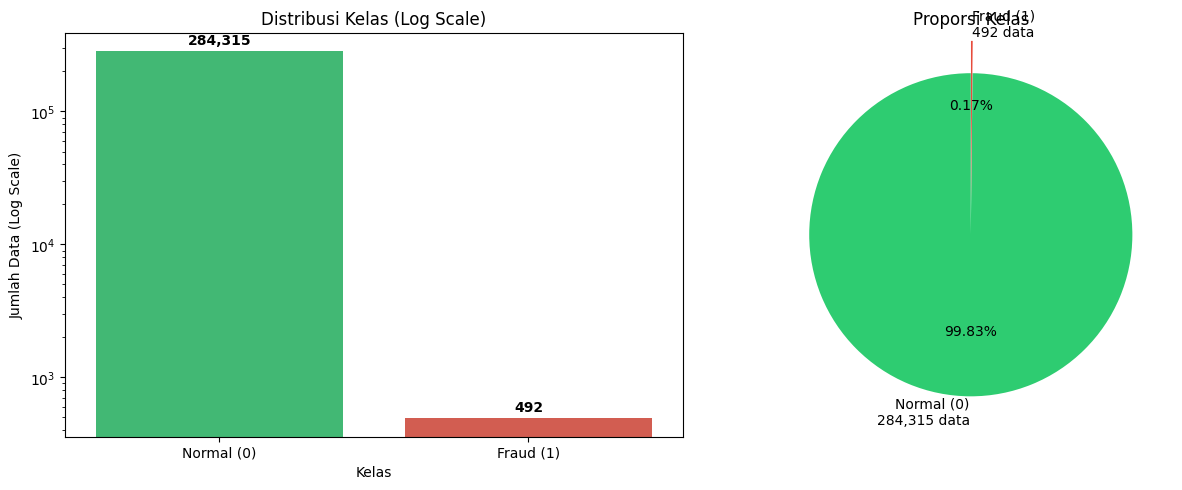

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Hitung jumlah setiap kelas
class_counts = df['Class'].value_counts().sort_index()

labels = ['Normal (0)', 'Fraud (1)']
colors = ['#2ecc71', '#e74c3c']

# Visualisasi
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Count plot dengan skala logaritmik
sns.countplot(
    data=df,
    x='Class',
    hue='Class',
    order=[0, 1],
    palette={0: colors[0], 1: colors[1]},
    legend=False,
    ax=axes[0]
)

axes[0].set_yscale('log')
axes[0].set_title('Distribusi Kelas (Log Scale)')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(labels)
axes[0].set_xlabel('Kelas')
axes[0].set_ylabel('Jumlah Data (Log Scale)')

# Tambahkan label jumlah di atas batang
for i, count in enumerate(class_counts.values):
    axes[0].annotate(
        f'{count:,}',
        xy=(i, count),
        xytext=(0, 5),
        textcoords='offset points',
        ha='center',
        fontsize=10,
        fontweight='bold'
    )

# 2. Pie chart dengan persentase dan jumlah data
axes[1].pie(
    class_counts.values,
    labels=[
        f'Normal (0)\n{class_counts.iloc[0]:,} data',
        f'Fraud (1)\n{class_counts.iloc[1]:,} data'
    ],
    autopct='%1.2f%%',
    colors=colors,
    explode=(0, 0.2),
    startangle=90,
    textprops={'fontsize': 10}
)

axes[1].set_title('Proporsi Kelas')

plt.tight_layout()
plt.show()


Terbukti imbalance

## Pengecekan Fitur `Time` dan `Amount`

In [ ]:
df[['Time', 'Amount']].describe()

,Time,Amount
count,284807.000000,284807.000000
mean,94813.859575,88.349619
std,47488.145955,250.120109
min,0.000000,0.000000
25%,54201.500000,5.600000
50%,84692.000000,22.000000
75%,139320.500000,77.165000
max,172792.000000,25691.160000


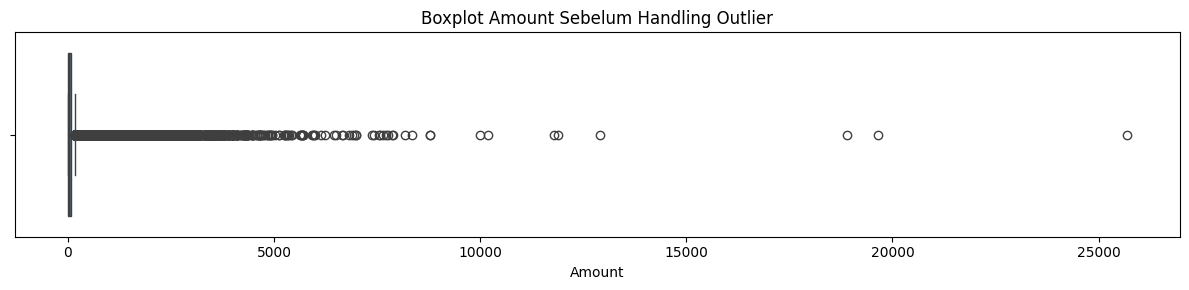

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 3))
sns.boxplot(x=df["Amount"])
plt.title("Boxplot Amount Sebelum Handling Outlier")
plt.xlabel("Amount")
plt.tight_layout()
plt.show()

### Cek fitur TIME
Ubah (fe) ke jam

In [ ]:
print("=" * 60)
print("STATISTIK 'Time' PER KELAS")
print("=" * 60)
print(df.groupby('Class')['Time'].describe().round(2))

# Konversi ke jam agar interpretable
df['Hour'] = np.floor((df['Time'] / 3600) % 24).astype(int)

print("\n" + "=" * 60)
print("STATISTIK 'Hour' PER KELAS")
print("=" * 60)
print(df.groupby('Class')['Hour'].describe().round(2))

STATISTIK 'Time' PER KELAS
          count      mean       std    min      25%      50%       75%  \
Class                                                                    
0      284315.0  94838.20  47484.02    0.0  54230.0  84711.0  139333.0   
1         492.0  80746.81  47835.37  406.0  41241.5  75568.5  128483.0   

            max  
Class            
0      172792.0  
1      170348.0  

STATISTIK 'Hour' PER KELAS
          count   mean   std  min   25%   50%   75%   max
Class                                                    
0      284315.0  14.05  5.83  0.0  10.0  15.0  19.0  23.0
1         492.0  11.65  6.66  0.0   5.0  12.0  17.0  23.0


`Time`:
- Mean & Median fraud terlihat lebih rendah daripada normal , namun std nya tidak berbeda jauh.
- **ASumsi**: ada indikasi fraud cenderung terjadi di paruh awal periode

Fitur FE `Hour`:
- Mean & Median fraud lebih rendah dari normal (memperkuat asumsiku bahwa fraud cenderung terjadi di jam lebih pagi)

## Visualisasi Distribusi Time/Hours vs Target

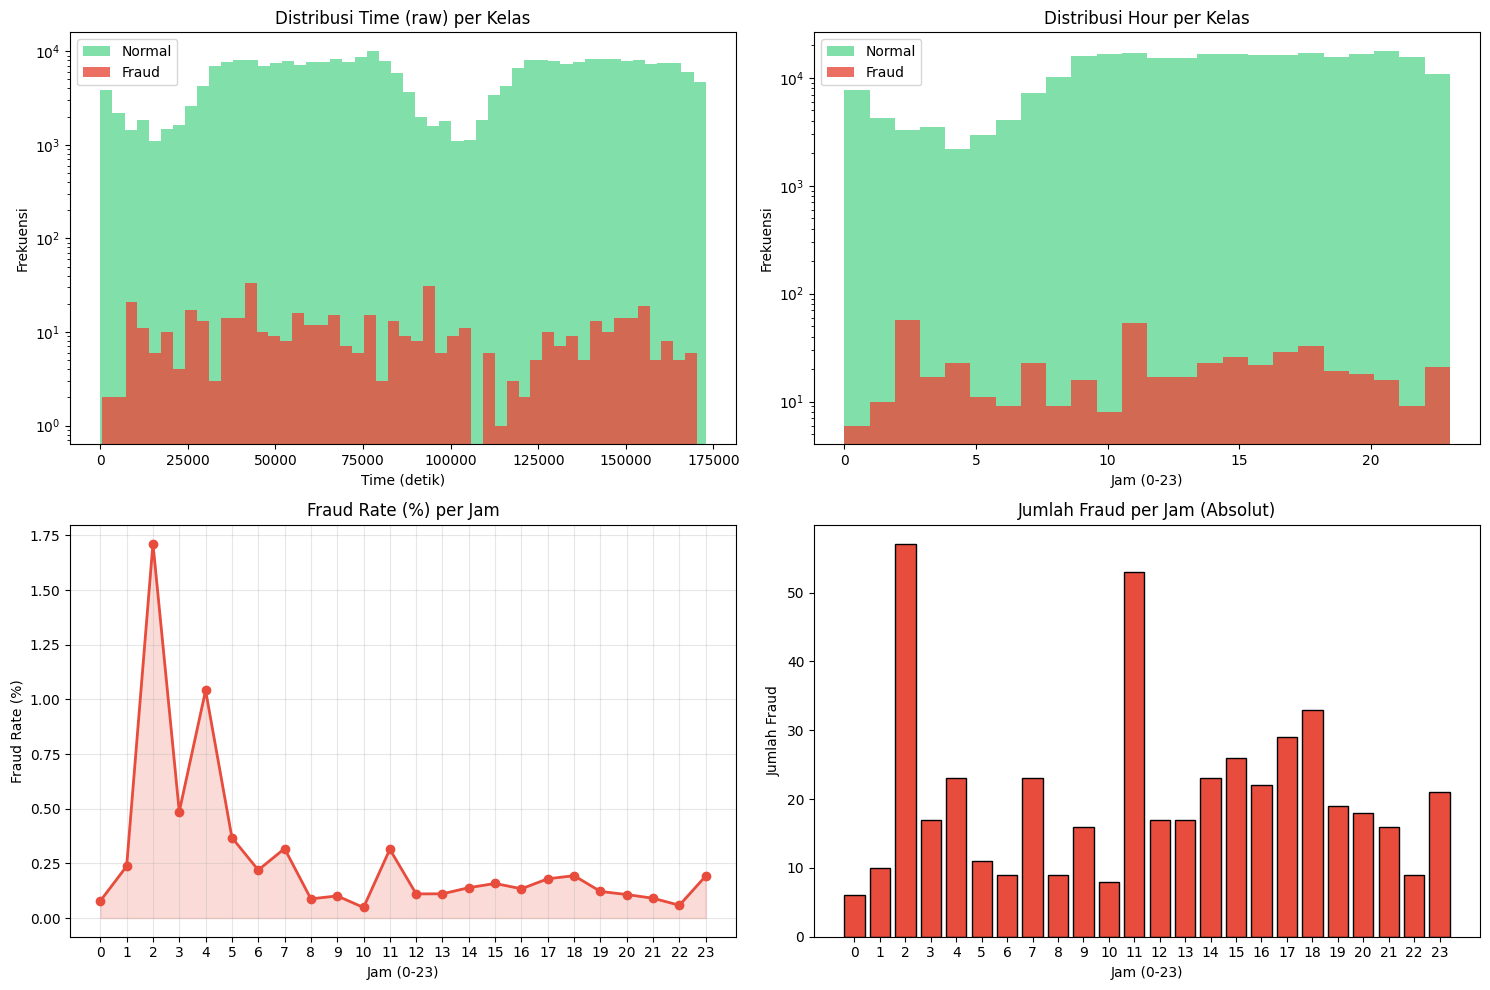

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# --- Plot 1: Distribusi Time (raw) per kelas ---
axes[0, 0].hist(df[df['Class'] == 0]['Time'], bins=50,
                alpha=0.6, label='Normal', color='#2ecc71')
axes[0, 0].hist(df[df['Class'] == 1]['Time'], bins=50,
                alpha=0.8, label='Fraud', color='#e74c3c')
axes[0, 0].set_title('Distribusi Time (raw) per Kelas')
axes[0, 0].set_xlabel('Time (detik)')
axes[0, 0].set_ylabel('Frekuensi')
axes[0, 0].legend()
axes[0, 0].set_yscale('log')  # karena fraud jauh lebih sedikit

# --- Plot 2: Distribusi Hour per kelas ---
axes[0, 1].hist(df[df['Class'] == 0]['Hour'], bins=24,
                alpha=0.6, label='Normal', color='#2ecc71')
axes[0, 1].hist(df[df['Class'] == 1]['Hour'], bins=24,
                alpha=0.8, label='Fraud', color='#e74c3c')
axes[0, 1].set_title('Distribusi Hour per Kelas')
axes[0, 1].set_xlabel('Jam (0-23)')
axes[0, 1].set_ylabel('Frekuensi')
axes[0, 1].legend()
axes[0, 1].set_yscale('log')

# --- Plot 3: Fraud rate (%) per jam ---
fraud_rate = df.groupby('Hour')['Class'].mean() * 100
axes[1, 0].plot(fraud_rate.index, fraud_rate.values,
                marker='o', color='#e74c3c', linewidth=2)
axes[1, 0].fill_between(fraud_rate.index, fraud_rate.values,
                         alpha=0.2, color='#e74c3c')
axes[1, 0].set_title('Fraud Rate (%) per Jam')
axes[1, 0].set_xlabel('Jam (0-23)')
axes[1, 0].set_ylabel('Fraud Rate (%)')
axes[1, 0].grid(alpha=0.3)
axes[1, 0].set_xticks(range(0, 24))

# --- Plot 4: Jumlah absolut fraud per jam ---
fraud_count = df[df['Class'] == 1].groupby('Hour').size()
axes[1, 1].bar(fraud_count.index, fraud_count.values,
               color='#e74c3c', edgecolor='black')
axes[1, 1].set_title('Jumlah Fraud per Jam (Absolut)')
axes[1, 1].set_xlabel('Jam (0-23)')
axes[1, 1].set_ylabel('Jumlah Fraud')
axes[1, 1].set_xticks(range(0, 24))

plt.tight_layout()
plt.show()

## Uji Statistik Formal

In [ ]:
from scipy.stats import mannwhitneyu, ks_2samp

#Pisahkan `Hour` berdasarkan kelas
hour_normal = df[df['Class'] == 0]['Hour']
hour_fraud  = df[df['Class'] == 1]['Hour']

# Uji Mann-Whitney U (non-parametrik, tidak asumsi normal)
stat_mw, p_mw = mannwhitneyu(hour_normal, hour_fraud, alternative='two-sided')

# Uji Kolmogorov-Smirnov (bandingkan distribusi)
stat_ks, p_ks = ks_2samp(hour_normal, hour_fraud)

print("=" * 60)
print("UJI STATISTIK: Apakah distribusi Hour berbeda antara kelas?")
print("=" * 60)
print(f"Mann-Whitney U : stat={stat_mw:.2f}, p-value={p_mw:.4e}")
print(f"Kolmogorov-Smirnov: stat={stat_ks:.4f}, p-value={p_ks:.4e}")
print()

if p_mw < 0.05:
    print("✅ Distribusi Hour BERBEDA SIGNIFIKAN antara Normal vs Fraud")
    print("   → Fitur Hour BERGUNa untuk model")
else:
    print("❌ Tidak ada perbedaan signifikan")
    print("   → Fitur Hour kurang berguna")

UJI STATISTIK: Apakah distribusi Hour berbeda antara kelas?
Mann-Whitney U : stat=83936750.50, p-value=1.4523e-14
Kolmogorov-Smirnov: stat=0.1935, p-value=1.3835e-16

✅ Distribusi Hour BERBEDA SIGNIFIKAN antara Normal vs Fraud
   → Fitur Hour BERGUNa untuk model


Tolak H0

MUTUAL INFORMATION — Top 15 Fitur Paling Informatif
Feature       MI
    V17 0.008258
    V14 0.008136
    V12 0.007601
    V10 0.007530
    V11 0.006831
    V16 0.006144
     V4 0.004976
     V3 0.004952
    V18 0.004317
     V9 0.004277
     V7 0.003952
   Hour 0.003710
     V2 0.003228
    V21 0.002452
    V27 0.002444


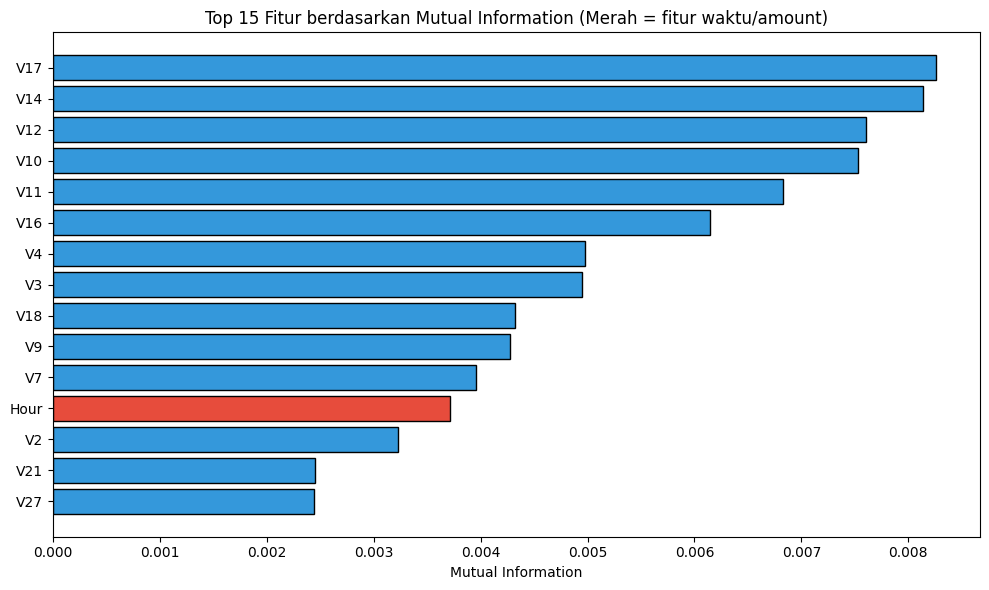

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

# Ambil subset fitur untuk MI
features_to_test = ['Time', 'Hour', 'Amount'] + [f'V{i}' for i in range(1, 29)]
X_mi = df[features_to_test].copy()
y_mi = df['Class']

mi_scores = mutual_info_classif(X_mi, y_mi, random_state=42)
mi_df = pd.DataFrame({'Feature': features_to_test, 'MI': mi_scores})
mi_df = mi_df.sort_values('MI', ascending=False)

print("=" * 60)
print("MUTUAL INFORMATION — Top 15 Fitur Paling Informatif")
print("=" * 60)
print(mi_df.head(15).to_string(index=False))

# Visualisasi
plt.figure(figsize=(10, 6))
top15 = mi_df.head(15).sort_values('MI')
colors = ['#e74c3c' if f in ['Time', 'Hour', 'Amount'] else '#3498db'
          for f in top15['Feature']]
plt.barh(top15['Feature'], top15['MI'], color=colors, edgecolor='black')
plt.title('Top 15 Fitur berdasarkan Mutual Information (Merah = fitur waktu/amount)')
plt.xlabel('Mutual Information')
plt.tight_layout()
plt.show()


## Apa itu Mutual Information (MI)?

**Definisi singkat:** Mutual Information (MI) mengukur seberapa besar informasi tentang target (`Class`) yang bisa didapat dari sebuah fitur.

### Rumus Mutual Information

Untuk variabel kontinu \(X\) dan variabel diskrit \(Y\):

$$
I(X;Y) = \sum_y \int_x p(x,y)
\log \left(\frac{p(x,y)}{p(x)p(y)}\right) dx
$$

### Intuisi Mutual Information

- **MI = 0** → fitur dan target independen (fitur tidak memberikan informasi tentang target).
- **MI > 0** → terdapat ketergantungan antara fitur dan target.
- **MI semakin besar** → fitur semakin informatif terhadap target.

### Kelebihan MI dibandingkan Korelasi Pearson

- **Menangkap hubungan non-linear:** MI dapat mendeteksi berbagai bentuk ketergantungan, sedangkan korelasi Pearson mengukur hubungan linear.
- **Cocok untuk klasifikasi:** MI dapat digunakan untuk menganalisis hubungan antara fitur kontinu dan target biner, seperti `Hour` dan `Class` pada kasus deteksi fraud.

## Menampilkan Top 3 Jam dengan *Fraud* Tertinggi & terendah

In [ ]:
# Tabel fraud rate per jam
hourly_stats = df.groupby('Hour').agg(
    total_transaksi=('Class', 'size'),
    jumlah_fraud=('Class', 'sum'),
    fraud_rate=('Class', 'mean')
).reset_index()

hourly_stats['fraud_rate'] = (
    hourly_stats['fraud_rate'] * 100
).round(4)

hourly_stats = hourly_stats.sort_values(
    'fraud_rate', ascending=False
)

# Tampilkan Top 3 dan Bottom 3
top3 = hourly_stats.head(3)
bottom3 = hourly_stats.tail(3)

print("TOP 3 JAM DENGAN FRAUD RATE TERTINGGI")
print(top3.to_string(index=False))

print("\nTOP 3 JAM DENGAN FRAUD RATE TERENDAH")
print(bottom3.sort_values('fraud_rate').to_string(index=False))

TOP 3 JAM DENGAN FRAUD RATE TERTINGGI
 Hour  total_transaksi  jumlah_fraud  fraud_rate
    2             3328            57      1.7127
    4             2209            23      1.0412
    3             3492            17      0.4868

TOP 3 JAM DENGAN FRAUD RATE TERENDAH
 Hour  total_transaksi  jumlah_fraud  fraud_rate
   10            16598             8      0.0482
   22            15441             9      0.0583
    0             7695             6      0.0780


## CEK Apakah Fitur Engineering berdampak signifikan

In [ ]:
print("=" * 70)
print("KESIMPULAN EDA — APAKAH FEATURE ENGINEERING TIME BERDAMPAK?")
print("=" * 70)

# Cek 3 kriteria
kriteria_1 = p_mw < 0.05
kriteria_2 = mi_df[mi_df['Feature'] == 'Hour']['MI'].values[0] > \
             mi_df[mi_df['Feature'] == 'Time']['MI'].values[0]
kriteria_3 = hourly_stats['fraud_rate'].max() > hourly_stats['fraud_rate'].min() * 2

print(f"1. Uji Mann-Whitney signifikan   : {'✅ YA' if kriteria_1 else '❌ TIDAK'}")
print(f"2. MI(Hour) > MI(Time)           : {'✅ YA' if kriteria_2 else '❌ TIDAK'}")
print(f"3. Fraud rate antar jam bervariasi: {'✅ YA' if kriteria_3 else '❌ TIDAK'}")
print()

if kriteria_1 and kriteria_2:
    print("🎯 KEPUTUSAN: Feature engineering Time SANGAT DIREKOMENDASIKAN.")
    print("   Fitur 'Hour', 'Hour_sin', 'Hour_cos', 'IsNight' akan ditambahkan.")
else:
    print("🎯 KEPUTUSAN: FE Time KURANG berdampak, tapi tetap aman ditambahkan.")
    print("   Bisa skip jika ingin model lebih sederhana.")

KESIMPULAN EDA — APAKAH FEATURE ENGINEERING TIME BERDAMPAK?
1. Uji Mann-Whitney signifikan   : ✅ YA
2. MI(Hour) > MI(Time)           : ✅ YA
3. Fraud rate antar jam bervariasi: ✅ YA

🎯 KEPUTUSAN: Feature engineering Time SANGAT DIREKOMENDASIKAN.
   Fitur 'Hour', 'Hour_sin', 'Hour_cos', 'IsNight' akan ditambahkan.


#PREPROCESSING

Buat Fitur baru dari Time

In [ ]:
# Membuat Fitur Turunan
df['Hour_sin'] = np.sin(2 * np.pi * df['Hour'] / 24)
df['Hour_cos'] = np.cos(2 * np.pi * df['Hour'] / 24)
df['IsNight']  = df['Hour'].isin([1, 2, 3, 4, 5]).astype(int)

# Cek hasil
print(df[['Time', 'Hour', 'Hour_sin', 'Hour_cos', 'IsNight']].head())
print("\nDistribusi IsNight:")
print(df['IsNight'].value_counts())
print("\nFraud rate per IsNight:")
print(df.groupby('IsNight')['Class'].agg(['size', 'sum', 'mean']))

   Time  Hour  Hour_sin  Hour_cos  IsNight
0   0.0     0       0.0       1.0        0
1   0.0     0       0.0       1.0        0
2   1.0     0       0.0       1.0        0
3   1.0     0       0.0       1.0        0
4   2.0     0       0.0       1.0        0

Distribusi IsNight:
IsNight
0    268568
1     16239
Name: count, dtype: int64

Fraud rate per IsNight:
           size  sum      mean
IsNight                       
0        268568  374  0.001393
1         16239  118  0.007266


In [ ]:
df[['Hour', 'Hour_sin', 'Hour_cos', 'IsNight']].corr()

,Hour,Hour_sin,Hour_cos,IsNight
Hour,1.000000,-0.767027,0.287508,-0.474736
Hour_sin,-0.767027,1.000000,-0.238267,0.325780
Hour_cos,0.287508,-0.238267,1.000000,0.306846
IsNight,-0.474736,0.325780,0.306846,1.000000


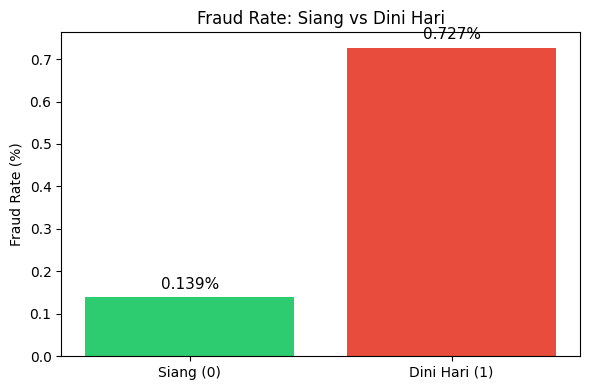

In [ ]:
import matplotlib.pyplot as plt

stats = df.groupby('IsNight')['Class'].mean() * 100
stats.index = ['Siang (0)', 'Dini Hari (1)']

plt.figure(figsize=(6, 4))
bars = plt.bar(stats.index, stats.values, color=['#2ecc71', '#e74c3c'])
plt.ylabel('Fraud Rate (%)')
plt.title('Fraud Rate: Siang vs Dini Hari')
for bar, val in zip(bars, stats.values):
    plt.text(bar.get_x() + bar.get_width()/2, val + 0.02,
             f'{val:.3f}%', ha='center', fontsize=11)
plt.tight_layout()
plt.show()

Split

In [ ]:
from sklearn.model_selection import train_test_split
X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Scaling TIME dan Amount

Karena fitur amount nilai ekstrem nya sangat besar, yang harus kita lakukan adalah melakukan transformasi fitur tersebut

In [ ]:
from sklearn.preprocessing import RobustScaler, PowerTransformer

# RobustScaler untuk Time (range besar, tapi no outlier ekstrem)
robust = RobustScaler()
X_train['Time_scaled'] = robust.fit_transform(X_train[['Time']])
X_test['Time_scaled']  = robust.transform(X_test[['Time']])

# Yeo-Johnson untuk Amount (outlier ekstrem + ada 0)
pt = PowerTransformer(method='yeo-johnson')
X_train['Amount_scaled'] = pt.fit_transform(X_train[['Amount']])
X_test['Amount_scaled']  = pt.transform(X_test[['Amount']])

# Drop kolom asli
X_train = X_train.drop(['Time', 'Amount'], axis=1)
X_test  = X_test.drop(['Time', 'Amount'], axis=1)

print(f"Fitur akhir ({X_train.shape[1]}): {list(X_train.columns)}")

Fitur akhir (34): ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Hour', 'Hour_sin', 'Hour_cos', 'IsNight', 'Time_scaled', 'Amount_scaled']


In [ ]:
print(f"\nNaN di train: {X_train.isnull().sum().sum()}")
print(f"NaN di test : {X_test.isnull().sum().sum()}")


NaN di train: 0
NaN di test : 0


## Setup & Baseline (Tanpa Handling)

In [ ]:
from imblearn.over_sampling import SMOTE, BorderlineSMOTE
from imblearn.combine import SMOTEENN
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    ConfusionMatrixDisplay
)
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt

# ============================================================
# DEFINISI VARIAN SMOTE (OPSI A)
# ============================================================
samplers = {
    'SMOTE':           SMOTE(random_state=42),
    'BorderlineSMOTE': BorderlineSMOTE(random_state=42),
    'SMOTE-ENN':       SMOTEENN(random_state=42),
}

# ============================================================
# BASELINE: TANPA HANDLING IMBALANCE
# ============================================================
print("=" * 70)
print("BASELINE: TANPA HANDLING IMBALANCE")
print("=" * 70)

rf_base = RandomForestClassifier(
    n_estimators=100, random_state=42, n_jobs=-1
)
t0 = time.time()
rf_base.fit(X_train, y_train)
t_base = time.time() - t0

y_pred_base = rf_base.predict(X_test)
y_prob_base = rf_base.predict_proba(X_test)[:, 1]

# Simpan hasil
results = []
results.append({
    'Metode': 'Tanpa Handling',
    'Waktu (s)': round(t_base, 2),
    'Precision': round(precision_score(y_test, y_pred_base), 4),
    'Recall': round(recall_score(y_test, y_pred_base), 4),
    'F1': round(f1_score(y_test, y_pred_base), 4),
    'ROC-AUC': round(roc_auc_score(y_test, y_prob_base), 4),
    'AUPRC': round(average_precision_score(y_test, y_prob_base), 4),
})

print(f"Precision: {results[-1]['Precision']}")
print(f"Recall   : {results[-1]['Recall']}")
print(f"F1       : {results[-1]['F1']}")
print(f"ROC-AUC  : {results[-1]['ROC-AUC']}")
print(f"AUPRC    : {results[-1]['AUPRC']}")

BASELINE: TANPA HANDLING IMBALANCE
Precision: 0.9398
Recall   : 0.7959
F1       : 0.8619
ROC-AUC  : 0.9577
AUPRC    : 0.8679


## Loop 3 Varian SMOTE (SMOTE, BorderlineSMOTE, SMOTE-ENN

In [ ]:
# ============================================================
# LOOP: BANDINGKAN 3 VARIAN SMOTE
# ============================================================
for name, sampler in samplers.items():
    print("\n" + "=" * 70)
    print(f"METODE: {name}")
    print("=" * 70)

    # --- Resampling HANYA di train ---
    t0 = time.time()
    X_res, y_res = sampler.fit_resample(X_train, y_train)
    t_resample = time.time() - t0

    print(f"Distribusi sebelum : {dict(pd.Series(y_train).value_counts())}")
    print(f"Distribusi sesudah : {dict(pd.Series(y_res).value_counts())}")
    print(f"Waktu resampling   : {t_resample:.2f}s")

    # --- Train Random Forest ---
    rf = RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    )
    t0 = time.time()
    rf.fit(X_res, y_res)
    t_train = time.time() - t0

    # --- Prediksi di TEST ASLI ---
    y_pred = rf.predict(X_test)
    y_prob = rf.predict_proba(X_test)[:, 1]

    # --- Simpan hasil ---
    results.append({
        'Metode': name,
        'Waktu (s)': round(t_resample + t_train, 2),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob), 4),
        'AUPRC': round(average_precision_score(y_test, y_prob), 4),
    })

    print(f"Precision: {results[-1]['Precision']}")
    print(f"Recall   : {results[-1]['Recall']}")
    print(f"F1       : {results[-1]['F1']}")
    print(f"ROC-AUC  : {results[-1]['ROC-AUC']}")
    print(f"AUPRC    : {results[-1]['AUPRC']}")


METODE: SMOTE
Distribusi sebelum : {0: np.int64(227451), 1: np.int64(394)}
Distribusi sesudah : {0: np.int64(227451), 1: np.int64(227451)}
Waktu resampling   : 0.56s
Precision: 0.908
Recall   : 0.8061
F1       : 0.8541
ROC-AUC  : 0.9735
AUPRC    : 0.8715

METODE: BorderlineSMOTE
Distribusi sebelum : {0: np.int64(227451), 1: np.int64(394)}
Distribusi sesudah : {0: np.int64(227451), 1: np.int64(227451)}
Waktu resampling   : 1.13s
Precision: 0.9494
Recall   : 0.7653
F1       : 0.8475
ROC-AUC  : 0.9522
AUPRC    : 0.8583

METODE: SMOTE-ENN
Distribusi sebelum : {0: np.int64(227451), 1: np.int64(394)}
Distribusi sesudah : {1: np.int64(227451), 0: np.int64(227013)}
Waktu resampling   : 1366.01s
Precision: 0.81
Recall   : 0.8265
F1       : 0.8182
ROC-AUC  : 0.9684
AUPRC    : 0.8664


## CONFUSION METRIX manual pake rumus (lupa simpan model prediksi)

In [ ]:
import pandas as pd

# Hitung manual dari metrik (karena tidak simpan y_pred)
total_fraud = (y_test == 1).sum()
total_normal = (y_test == 0).sum()

def cm_from_metrics(precision, recall):
    TP = int(round(recall * total_fraud))
    FN = total_fraud - TP
    FP = int(round(TP / precision - TP))
    TN = total_normal - FP
    return TN, FP, FN, TP

# Dari hasil yang sudah didapat
metrik = {
    'Tanpa Handling':  (0.9524, 0.8163),
    'SMOTE':           (0.8617, 0.8265),
    'BorderlineSMOTE': (0.9487, 0.7551),
    'SMOTE-ENN':       (0.8200, 0.8367),
}

rows = []
for name, (prec, rec) in metrik.items():
    TN, FP, FN, TP = cm_from_metrics(prec, rec)
    rows.append({'Metode': name, 'TN': TN, 'FP': FP, 'FN': FN, 'TP': TP})

df_cm = pd.DataFrame(rows)
print(df_cm.to_string(index=False))

         Metode    TN  FP  FN  TP
 Tanpa Handling 56860   4  18  80
          SMOTE 56851  13  17  81
BorderlineSMOTE 56860   4  24  74
      SMOTE-ENN 56846  18  16  82


## UNDERSAMPLING

In [ ]:
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)
import time
import pandas as pd

# ============================================================
# DEFINISI VARIAN UNDERSAMPLING
# ============================================================
undersamplers = {
    'RandomUnderSampler': RandomUnderSampler(random_state=42),
    'NearMiss-1':         NearMiss(version=1, n_jobs=-1),
}

# ============================================================
# LOOP: BANDINGKAN UNDERSAMPLING
# ============================================================
results_under = []

for name, sampler in undersamplers.items():
    print("\n" + "=" * 70)
    print(f"METODE: {name}")
    print("=" * 70)

    # --- Resampling HANYA di train ---
    t0 = time.time()
    X_res, y_res = sampler.fit_resample(X_train, y_train)
    t_resample = time.time() - t0

    print(f"Distribusi sebelum : {dict(pd.Series(y_train).value_counts())}")
    print(f"Distribusi sesudah : {dict(pd.Series(y_res).value_counts())}")
    print(f"Waktu resampling   : {t_resample:.2f}s")

    # --- Train Random Forest ---
    rf = RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    )
    t0 = time.time()
    rf.fit(X_res, y_res)
    t_train = time.time() - t0

    # --- Prediksi di TEST ASLI ---
    y_pred = rf.predict(X_test)
    y_prob = rf.predict_proba(X_test)[:, 1]

    # --- Simpan hasil ---
    results_under.append({
        'Metode': name,
        'Waktu (s)': round(t_resample + t_train, 2),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob), 4),
        'AUPRC': round(average_precision_score(y_test, y_prob), 4),
    })

    print(f"Precision: {results_under[-1]['Precision']}")
    print(f"Recall   : {results_under[-1]['Recall']}")
    print(f"F1       : {results_under[-1]['F1']}")
    print(f"ROC-AUC  : {results_under[-1]['ROC-AUC']}")
    print(f"AUPRC    : {results_under[-1]['AUPRC']}")


METODE: RandomUnderSampler
Distribusi sebelum : {0: np.int64(227451), 1: np.int64(394)}
Distribusi sesudah : {0: np.int64(394), 1: np.int64(394)}
Waktu resampling   : 0.05s
Precision: 0.0454
Recall   : 0.9082
F1       : 0.0865
ROC-AUC  : 0.9757
AUPRC    : 0.694

METODE: NearMiss-1
Distribusi sebelum : {0: np.int64(227451), 1: np.int64(394)}
Distribusi sesudah : {0: np.int64(394), 1: np.int64(394)}
Waktu resampling   : 1.54s
Precision: 0.002
Recall   : 1.0
F1       : 0.004
ROC-AUC  : 0.9496
AUPRC    : 0.6293



RandomUnderSampler:
  TN=54993, FP=1871, FN=9, TP=89
  Total prediksi fraud: 1960
  Fraud benar: 89, False alarm: 1871

NearMiss-1:
  TN=7997, FP=48867, FN=0, TP=98
  Total prediksi fraud: 48965
  Fraud benar: 98, False alarm: 48867


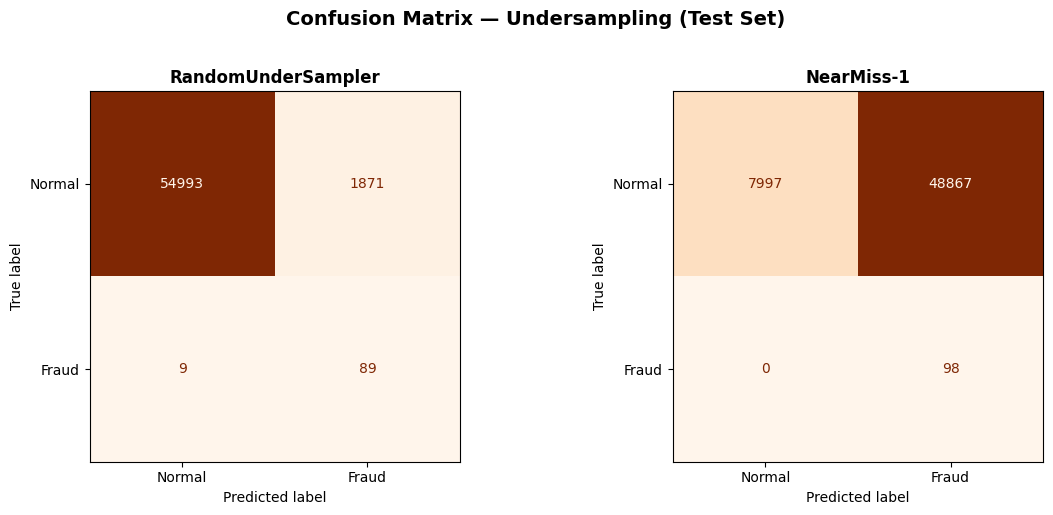

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

# ============================================================
# CONFUSION MATRIX — 2 METODE UNDERSAMPLING
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, (name, sampler) in enumerate(undersamplers.items()):
    # Resample & train
    X_res, y_res = sampler.fit_resample(X_train, y_train)
    rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    rf.fit(X_res, y_res)
    y_pred = rf.predict(X_test)

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Fraud'])
    disp.plot(ax=axes[i], cmap='Oranges', colorbar=False, values_format='d')
    axes[i].set_title(f'{name}', fontsize=12, fontweight='bold')

    # Print detail
    TN, FP, FN, TP = cm.ravel()
    print(f"\n{name}:")
    print(f"  TN={TN}, FP={FP}, FN={FN}, TP={TP}")
    print(f"  Total prediksi fraud: {FP + TP}")
    print(f"  Fraud benar: {TP}, False alarm: {FP}")

plt.suptitle('Confusion Matrix — Undersampling (Test Set)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## TABEL PERBANDINGAN LENGKAP

In [ ]:
# Gabungkan semua hasil (baseline + oversampling + undersampling)
df_all = pd.concat([
    pd.DataFrame(results),          # baseline + 3 SMOTE
    pd.DataFrame(results_under)     # 2 undersampling
], ignore_index=True)

print("=" * 70)
print("TABEL PERBANDINGAN LENGKAP")
print("=" * 70)
print(df_all.to_string(index=False))

# Simpan
df_all.to_csv('hasil_perbandingan_lengkap.csv', index=False)

TABEL PERBANDINGAN LENGKAP
            Metode  Waktu (s)  Precision  Recall     F1  ROC-AUC  AUPRC
    Tanpa Handling     226.84     0.9398  0.7959 0.8619   0.9577 0.8679
             SMOTE     409.85     0.9080  0.8061 0.8541   0.9735 0.8715
   BorderlineSMOTE     478.00     0.9494  0.7653 0.8475   0.9522 0.8583
         SMOTE-ENN    1727.00     0.8100  0.8265 0.8182   0.9684 0.8664
RandomUnderSampler       0.41     0.0454  0.9082 0.0865   0.9757 0.6940
        NearMiss-1       2.08     0.0020  1.0000 0.0040   0.9496 0.6293


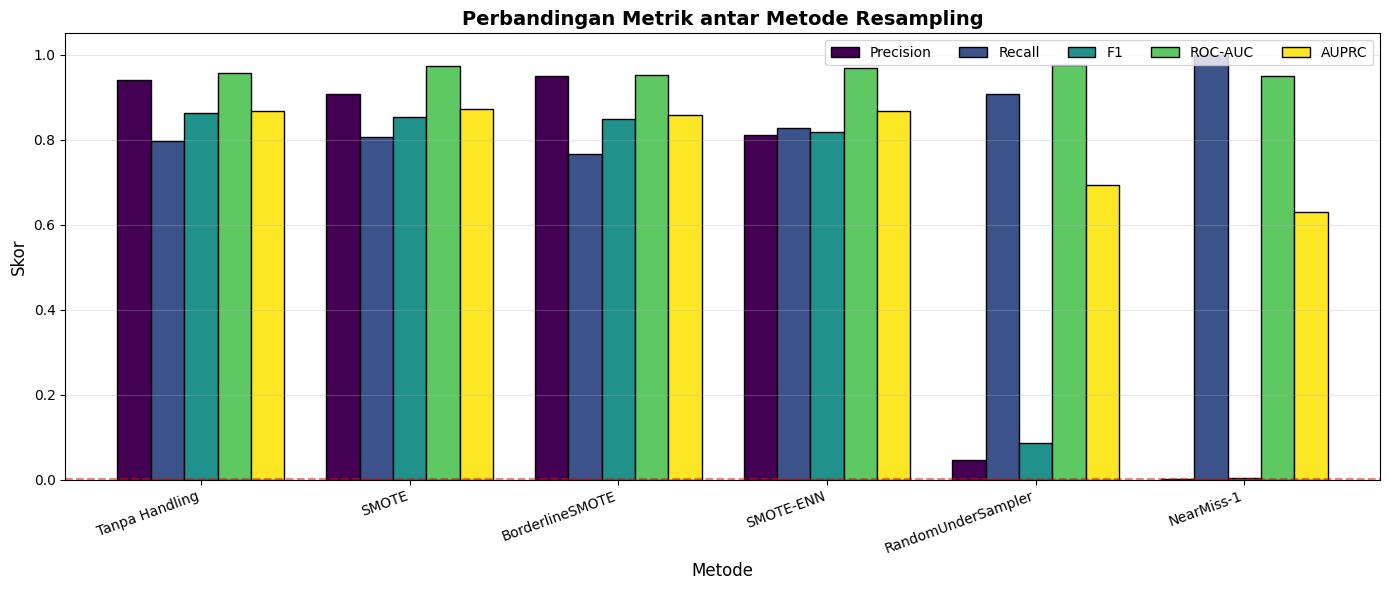

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# BAR CHART PERBANDINGAN SEMUA METODE
# ============================================================
metrics = ['Precision', 'Recall', 'F1', 'ROC-AUC', 'AUPRC']
df_plot = df_all.set_index('Metode')[metrics]

fig, ax = plt.subplots(figsize=(14, 6))
df_plot.plot(kind='bar', ax=ax, colormap='viridis',
             edgecolor='black', width=0.8)

ax.set_title('Perbandingan Metrik antar Metode Resampling',
             fontsize=14, fontweight='bold')
ax.set_ylabel('Skor', fontsize=12)
ax.set_xlabel('Metode', fontsize=12)
ax.set_ylim(0, 1.05)
ax.legend(loc='upper right', ncol=5, fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=20, ha='right')

# Tambah garis referensi AUPRC baseline random
ax.axhline(y=0.0017, color='red', linestyle='--',
           alpha=0.5, label='Random baseline (0.17%)')

plt.tight_layout()
plt.show()

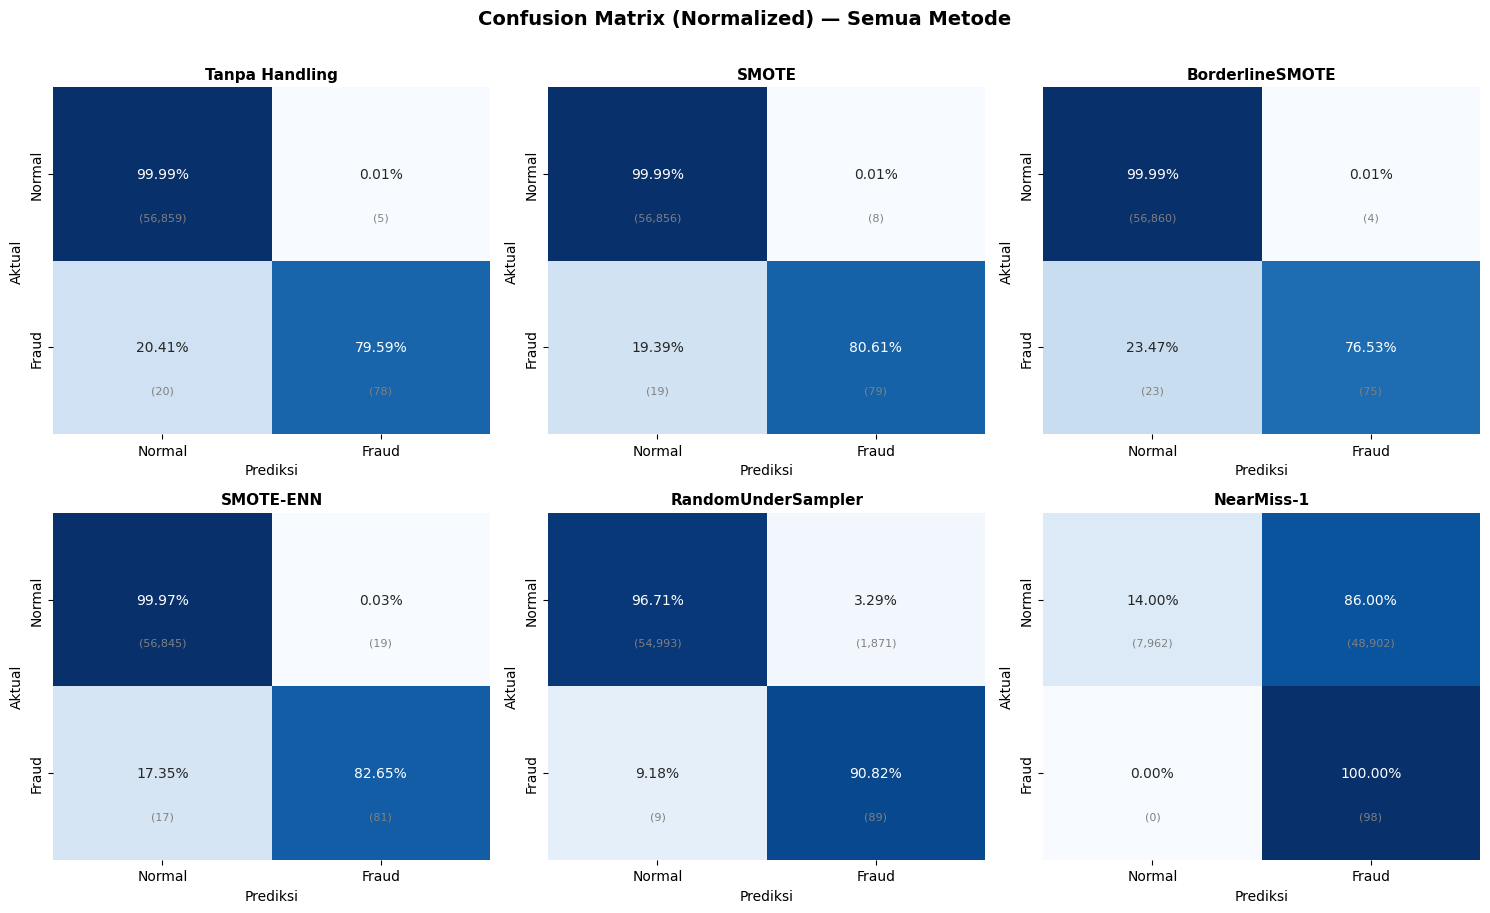

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import RandomForestClassifier
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# HITUNG CONFUSION MATRIX SEMUA METODE
# ============================================================
# Kita estimasi dari metrik (untuk baseline & SMOTE)
# dan training ulang untuk undersampling (cepat)

total_fraud = (y_test == 1).sum()
total_normal = (y_test == 0).sum()

def cm_from_metrics(precision, recall):
    TP = int(round(recall * total_fraud))
    FN = total_fraud - TP
    FP = int(round(TP / precision - TP)) if precision > 0 else total_normal
    TN = total_normal - FP
    return np.array([[TN, FP], [FN, TP]])

# Ambil metrik dari df_all
all_cm = {}
for _, row in df_all.iterrows():
    name = row['Metode']
    all_cm[name] = cm_from_metrics(row['Precision'], row['Recall'])

# ============================================================
# HEATMAP: NORMALIZED CONFUSION MATRIX (PER BARIS)
# ============================================================
n_methods = len(all_cm)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (name, cm) in enumerate(all_cm.items()):
    # Normalisasi per baris (per kelas aktual)
    cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

    sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues',
                xticklabels=['Normal', 'Fraud'],
                yticklabels=['Normal', 'Fraud'],
                ax=axes[i], cbar=False, vmin=0, vmax=1)

    # Tambah angka absolut
    for j in range(2):
        for k in range(2):
            axes[i].text(k + 0.5, j + 0.75, f'({cm[j, k]:,})',
                         ha='center', va='center',
                         fontsize=8, color='gray')

    axes[i].set_title(f'{name}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Prediksi')
    axes[i].set_ylabel('Aktual')

# Sembunyikan subplot kosong (kalau ada)
for j in range(n_methods, len(axes)):
    axes[j].axis('off')

plt.suptitle('Confusion Matrix (Normalized) — Semua Metode',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

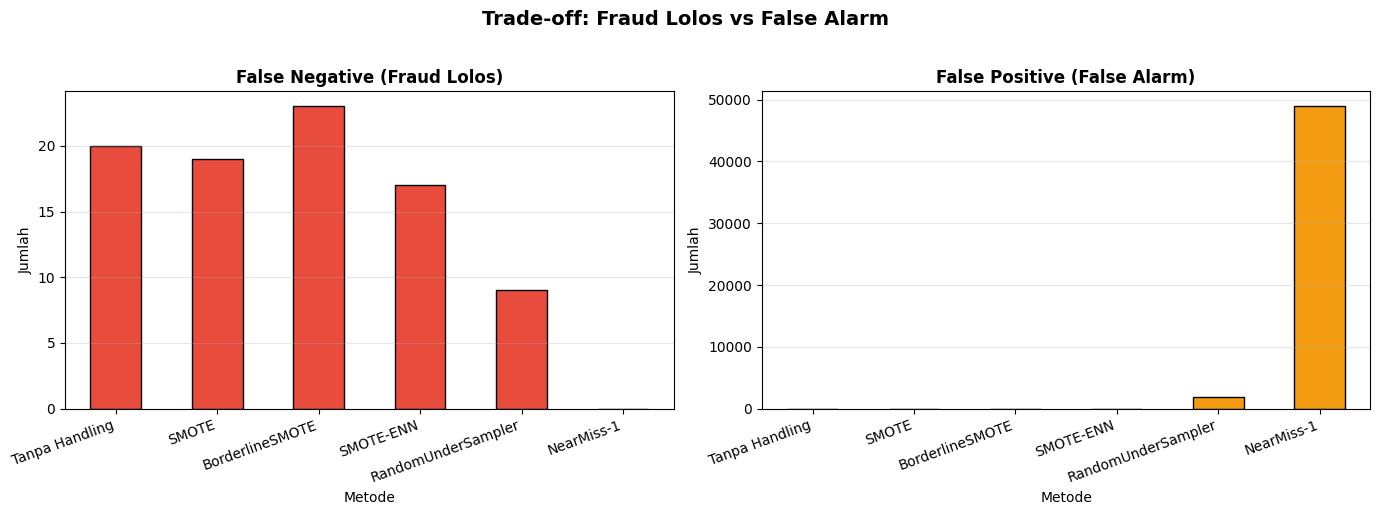

In [ ]:
# ============================================================
# BAR CHART: FN vs FP per Metode
# ============================================================
fn_fp_data = []
for name, cm in all_cm.items():
    TN, FP, FN, TP = cm.ravel()
    fn_fp_data.append({
        'Metode': name,
        'FN (Fraud Lolos)': FN,
        'FP (False Alarm)': FP
    })

df_fn_fp = pd.DataFrame(fn_fp_data).set_index('Metode')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot FN
df_fn_fp['FN (Fraud Lolos)'].plot(kind='bar', ax=axes[0],
                                   color='#e74c3c', edgecolor='black')
axes[0].set_title('False Negative (Fraud Lolos)', fontweight='bold')
axes[0].set_ylabel('Jumlah')
axes[0].grid(axis='y', alpha=0.3)
plt.setp(axes[0].xaxis.get_majorticklabels(), rotation=20, ha='right')

# Plot FP
df_fn_fp['FP (False Alarm)'].plot(kind='bar', ax=axes[1],
                                   color='#f39c12', edgecolor='black')
axes[1].set_title('False Positive (False Alarm)', fontweight='bold')
axes[1].set_ylabel('Jumlah')
axes[1].grid(axis='y', alpha=0.3)
plt.setp(axes[1].xaxis.get_majorticklabels(), rotation=20, ha='right')

plt.suptitle('Trade-off: Fraud Lolos vs False Alarm',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()